In [ ]:
%pip install puremacro


# Quantitative Spatial Economics and Trade General Equilibrium: Caliendo-Parro Input-Output Hat Algebra and Allen-Arkolakis Economic Geography

**How do international tariff shocks, supply chain disruptions, and regional transport infrastructure investments propagate through domestic and global input-output linkages and spatial labor mobility to reshape trade flows, regional population distributions, and aggregate economic welfare?**

In modern international trade and spatial economics, localized policy interventions and geographic frictions do not operate in isolation. In the global trade sphere, production processes are deeply fragmented across international borders: intermediate inputs account for over half of total world trade, meaning tariffs imposed on upstream components cascade downstream through input-output networks, distorting relative prices, deflecting trade flows toward third nations, and generating complex general equilibrium welfare consequences. Concurrently, within geographic space, workers and firms respond endogenously to transport cost reductions: lower shipping costs expand market access, inducing labor migration toward high-access regions until centripetal agglomeration spillovers are balanced by centrifugal congestion in housing and amenities.

This showcase notebook implements, solves, and analyzes the two foundational general equilibrium frameworks of quantitative spatial and trade economics:
1. The **Caliendo-Parro (2015)** multi-country, multi-sector Ricardian trade model with intermediate input-output linkages, sector-specific trade elasticities, tariffs, and trade imbalances, solved via Exact Hat Algebra.
2. The **Allen-Arkolakis (2014)** continuous geographic spatial general equilibrium model with bilateral iceberg trade costs, productivity agglomeration, amenity congestion, and freely mobile labor across space.

## The method in math — Quantitative Trade and Spatial General Equilibrium

**1. Caliendo & Parro (2015) Exact Hat Algebra with Input-Output Linkages.**
Consider an international economy with $N$ countries ($i, n = 1, \dots, N$) and $J$ sectors ($j, k = 1, \dots, J$). Representative households in country $n$ maximize Cobb-Douglas utility over sectoral composite goods with expenditure shares $\alpha_n^j$ ($\sum_{j=1}^J \alpha_n^j = 1$):
$$ U_n = \prod_{j=1}^J (C_n^j)^{\alpha_n^j}. $$
Sectoral output $Y_n^j$ is produced combining labor (with value-added share $\gamma_n^j > 0$) and intermediate inputs from all sectors $k=1, \dots, J$ (with cost shares $\gamma_n^{j, k} \ge 0$), under constant returns to scale:
$$ \gamma_n^j + \sum_{k=1}^J \gamma_n^{j, k} = 1, \qquad c_n^j = \Upsilon_n^j w_n^{\gamma_n^j} \prod_{k=1}^J (P_n^k)^{\gamma_n^{j, k}}, $$
where $c_n^j$ denotes the unit cost of the input bundle and $\Upsilon_n^j$ is a technology constant. In Exact Hat Algebra (where $\hat{x} \equiv x' / x$ denotes the proportional change between the counterfactual and baseline equilibrium), the unit cost changes as:
$$ \ln \hat{c}_i^j = \gamma_i^j \ln \hat{w}_i + \sum_{k=1}^J \gamma_i^{j, k} \ln \hat{P}_i^k. $$
Goods within sector $j$ are traded internationally subject to iceberg shipping costs $d_{ni}^j \ge 1$ and gross ad-valorem tariffs $\tau_{ni}^j = 1 + t_{ni}^j \ge 1$, yielding total trade costs $\kappa_{ni}^j = \tau_{ni}^j d_{ni}^j$. Under Eaton & Kortum (2002) Fréchet productivity dispersion with sector-specific trade elasticity $\theta_j > 0$, the change in the sectoral price index $\hat{P}_n^j$ and counterfactual bilateral expenditure shares $\pi_{ni}'^j$ satisfy:
$$ \hat{P}_n^j = \left[ \sum_{i=1}^N \pi_{ni}^j \left( \hat{c}_i^j \hat{\tau}_{ni}^j \hat{d}_{ni}^j \right)^{-\theta_j} \right]^{-1/\theta_j}, \qquad \pi_{ni}'^j = \pi_{ni}^j \left( \frac{\hat{c}_i^j \hat{\tau}_{ni}^j \hat{d}_{ni}^j}{\hat{P}_n^j} \right)^{-\theta_j}. $$
Total national expenditure $I_n'$ combines counterfactual labor income $w_n' L_n$, tariff revenues $R_n'$, and the counterfactual trade deficit $D_n'$ ($I_n' = w_n' L_n + R_n' + D_n'$). Sectoral expenditure $X_n'^j$ and gross output $Y_i'^j$ satisfy the market clearing identities:
$$ X_n'^j = \alpha_n^j I_n' + \sum_{k=1}^J \gamma_n^{k, j} Y_n'^k, \qquad Y_i'^j = \sum_{n=1}^N \frac{\pi_{ni}'^j}{\tau_{ni}'^j} X_n'^j, \qquad w_n' L_n = \sum_{j=1}^J \gamma_n^j Y_n'^j. $$
Counterfactual real wage changes and national welfare percentage changes are given by:
$$ \widehat{\left(\frac{w_n}{P_n}\right)} = \frac{\hat{w}_n}{\prod_{j=1}^J (\hat{P}_n^j)^{\alpha_n^j}}, \qquad \hat{W}_n = \frac{\hat{I}_n}{\prod_{j=1}^J (\hat{P}_n^j)^{\alpha_n^j}}, \qquad \Delta W_n (\%) = (\hat{W}_n - 1) \times 100. $$

**2. Allen & Arkolakis (2014) Quantitative Spatial General Equilibrium.**
Consider a continuous geographic economy with $N$ locations, total population $\bar{L} = \sum_{i=1}^N L_i$, and bilateral iceberg trade costs $\tau_{ij} \ge 1$ ($\tau_{ii} = 1$). Indirect utility in location $i$ depends on real wages and local amenities $a_i$:
$$ u_i = a_i \frac{w_i}{P_i}, \qquad a_i = \bar{a}_i L_i^\beta, $$
where $\bar{a}_i > 0$ denotes fundamental amenities and $\beta < 0$ captures amenity congestion (e.g. land, housing scarcity, or commuting frictions). Free labor mobility equalizes real utility across all populated regions ($u_i = \bar{u}$), yielding the equilibrium population distribution:
$$ L_i = \bar{L} \frac{\left(\bar{a}_i w_i / P_i\right)^{-1/\beta}}{\sum_{k=1}^N \left(\bar{a}_k w_k / P_k\right)^{-1/\beta}}. $$
The CES price index $P_i$ and firm market access $\text{FMA}_i$ depend on trade elasticity $\theta$ and local productivity $A_j = \bar{A}_j L_j^\alpha$, where $\alpha > 0$ captures Marshallian agglomeration spillovers:
$$ P_i^{-\theta} = \sum_{j=1}^N \tau_{ji}^{-\theta} \left( \frac{w_j}{\bar{A}_j L_j^\alpha} \right)^{-\theta}, \qquad \text{FMA}_i = \sum_{j=1}^N \tau_{ij}^{-\theta} P_j^\theta w_j L_j. $$
Goods market clearing ($w_i L_i = \sum_j \pi_{ji} w_j L_j$) determines equilibrium wages:
$$ w_i^{1 + \theta} = (\bar{A}_i L_i^\alpha)^\theta L_i^{-1} \text{FMA}_i. $$
A unique spatial general equilibrium is guaranteed whenever parameters satisfy Theorem 2 of Allen & Arkolakis (2014): $\alpha + \beta \le \frac{\theta}{1 + \theta}$ and $\alpha \le \frac{1}{\theta}$.

## Intuition

**Intuition.** Quantitative spatial and trade models reveal how localized shocks propagate through macroeconomic networks, transforming localized price signals into systemic reallocations of production, labor, and economic welfare.

In international trade, the **Caliendo-Parro (2015)** framework highlights two decisive propagation channels:
1. **Trade Diversion and Terms-of-Trade Manipulation:** When Country A raises tariffs on imports from Country B, the direct price of B's goods rises inside A. Because varieties are imperfect substitutes governed by the trade elasticity $\theta_j$, domestic consumers and downstream producers substitute away from B toward non-tariffed trading partners (the Rest of the World) and domestic suppliers. While Country A may temporarily extract tariff revenue and improve its terms of trade in a unilateral tariff shock, a reciprocal trade war triggers retaliatory barriers, eliminating terms-of-trade advantages and leaving both nations with deadweight losses from distorted production and reduced real income.
2. **Supply Chain Multipliers:** Traditional trade models assume goods are produced purely from primary factors (labor and capital). In reality, manufacturing sectors rely intensely on intermediate inputs. When tariffs increase the cost of imported steel or electronics, downstream automotive, aerospace, and machinery sectors face rising production costs $\hat{c}_i^j$. These cost surges cascade through domestic input-output tables ($\gamma_i^{j, k}$) and cross borders again via intermediate exports, compounding tariff distortions and multiplying welfare losses across the global economy. Crucially, **Exact Hat Algebra** solves this complex general equilibrium system using only observable baseline trade shares $\pi_{ni}^j$, input-output coefficients $\gamma_n^{j, k}$, and trade elasticities $\theta_j$—completely bypassing the need to estimate unobserved fundamental productivity levels or physical trade barriers.

In geographic space, the **Allen-Arkolakis (2014)** model demonstrates the interplay between centripetal and centrifugal spatial forces:
- **Market Access Expansion:** Transport infrastructure improvements (such as high-speed rail corridors, highway networks, or port modernizations) reduce bilateral iceberg frictions $\tau_{ij}$. This immediately expands Consumer Market Access ($\text{CMA}_i = P_i^{-\theta}$), lowering local import price indices, while expanding Firm Market Access ($\text{FMA}_i$), allowing local firms to sell more profitably across broader geographic markets.
- **Agglomeration vs. Congestion Equilibrium:** The initial boost to real wages ($w_i / P_i$) attracts mobile workers from peripheral regions. As labor concentrates in connected hub locations, **agglomeration economies** ($\alpha > 0$) amplify productivity through thicker labor markets, specialized input sharing, and knowledge spillovers. However, unlimited clustering is constrained by **amenity congestion** ($\beta < 0$): as population concentrates, housing becomes scarce, rents rise, and infrastructure becomes congested. The spatial general equilibrium achieves balance when the real utility of workers is perfectly equalized across all regions ($u_i = \bar{u}$), conserving the aggregate national population mass while generating positive aggregate welfare gains.

In [1]:
# Preamble: import numerical libraries, plotting style, and GE solvers
import sys
from pathlib import Path
import warnings

import numpy as np
import matplotlib.pyplot as plt

_cwd = Path.cwd()
sys.path.insert(0, str(_cwd if (_cwd / "_nbstyle.py").exists() else _cwd / "notebooks"))
import _nbstyle
_nbstyle.apply_style()

from puremacro.trade.caliendo_parro import CaliendoParroModel
from puremacro.spatial.allen_arkolakis import AllenArkolakisModel

# Set deterministic random seed for reproducibility
rng = np.random.default_rng(42)

# --- Caliendo-Parro (2015) 3-Country, 2-Sector Global Economy Calibration ---
N_cp, J_cp = 3, 2
country_codes = ["USA", "CHN", "ROW"]
sector_codes = ["Manufactures", "Services"]

# Bilateral trade shares: shape (J, N, N) where pi[j, n, i] = share of n on i
trade_shares = np.array([
    [[0.55, 0.25, 0.20], [0.15, 0.70, 0.15], [0.25, 0.25, 0.50]],
    [[1.00, 0.00, 0.00], [0.00, 1.00, 0.00], [0.00, 0.00, 1.00]],
], dtype=float)

# Value-added shares gamma_va: shape (N, J)
gamma_va = np.array([[0.40, 0.60], [0.35, 0.65], [0.45, 0.55]])

# Input-output coefficients gamma_io: shape (N, J, J)
gamma_io = np.zeros((N_cp, J_cp, J_cp))
for n in range(N_cp):
    for j in range(J_cp):
        rem = 1.0 - gamma_va[n, j]
        gamma_io[n, j, 0] = rem * 0.60
        gamma_io[n, j, 1] = rem * 0.40

# Final consumption expenditure shares alpha: shape (N, J)
alpha = np.array([[0.30, 0.70], [0.45, 0.55], [0.35, 0.65]])

# Sectoral trade elasticities theta: shape (J,)
theta_cp = np.array([5.0, 4.0])

# Baseline labor income (GDP) and initial trade deficits: shape (N,)
labor_income = np.array([120.0, 90.0, 100.0])
deficits = np.array([10.0, -10.0, 0.0])

# Construct baseline Caliendo-Parro model
cp_model = CaliendoParroModel(
    trade_shares=trade_shares,
    gamma_va=gamma_va,
    gamma_io=gamma_io,
    alpha=alpha,
    theta=theta_cp,
    labor_income=labor_income,
    deficits=deficits,
    nontradables=[1],
    country_codes=country_codes,
    sector_codes=sector_codes,
)

# --- Allen-Arkolakis (2014) 5-Region Spatial Geography Setup ---
region_names = ["North", "South", "East", "West", "Central"]
coords = np.array([
    [45.0, -93.0],
    [30.0, -90.0],
    [40.7, -74.0],
    [37.7, -122.4],
    [38.6, -90.2],
])

aa_model = AllenArkolakisModel.from_coordinates(
    coords,
    region_names=region_names,
    theta=4.0,
    alpha=0.08,
    beta=-0.35,
    total_population=100.0,
)

print(f"Caliendo-Parro Model: {N_cp} countries, {J_cp} sectors ({sector_codes[0]}: Tradable, {sector_codes[1]}: Non-Tradable)")
print(f"Allen-Arkolakis Model: {len(region_names)} regions, Total Population = {aa_model.total_population:.1f}")
print(f"Spatial Uniqueness Condition Satisfied: {aa_model.is_unique}")

Caliendo-Parro Model: 3 countries, 2 sectors (Manufactures: Tradable, Services: Non-Tradable)
Allen-Arkolakis Model: 5 regions, Total Population = 100.0
Spatial Uniqueness Condition Satisfied: True


--- Experiment 1: Caliendo-Parro Simulation Diagnostics ---
Unilateral Tariff: Converged = True | Residual = 2.99e-09
  USA Welfare Change: +0.33% | Tariff Revenue = 2.15
  CHN Welfare Change: -0.22% | Tariff Revenue = 0.00
  ROW Welfare Change: -1.16% | Tariff Revenue = 0.00

Reciprocal Trade War (25%): Converged = True | Residual = 7.77e-09
  USA Welfare Change: -1.11%
  CHN Welfare Change: -0.69%
  ROW Welfare Change: -0.90%


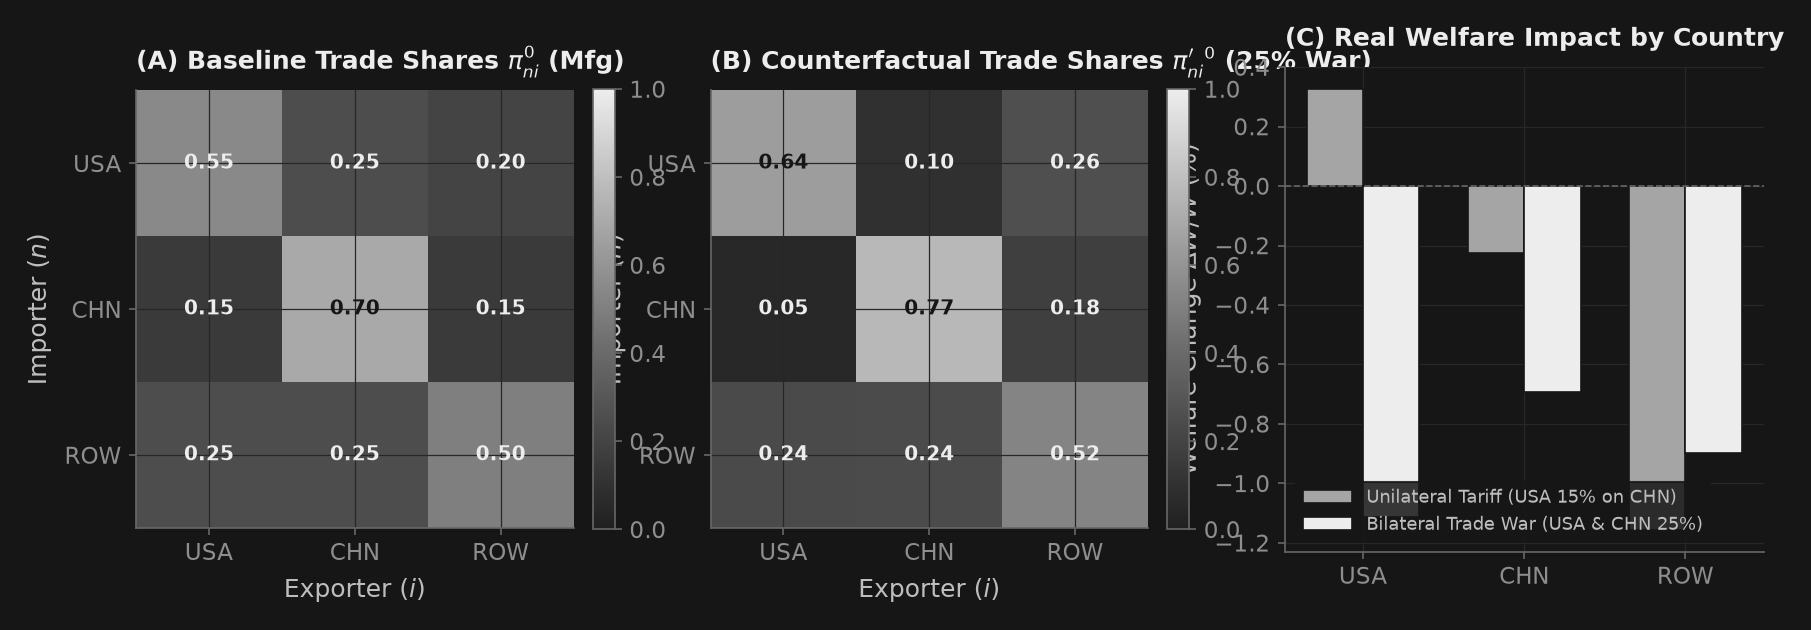

In [2]:
# --- Experiment 1: Tariffs, Trade Diversion, and Trade Wars (Caliendo-Parro 2015) ---
# 1. Unilateral tariff shock: USA imposes 15% tariff on Chinese manufactures
uni_res = cp_model.simulate_tariff_shock(
    importer="USA", exporter="CHN", sector="Manufactures", tariff_rate=0.15
)

# 2. Reciprocal bilateral trade war: USA and China impose 25% tariffs on each other across all tradables
war_res = cp_model.simulate_trade_war(
    coalition_a=["USA"], coalition_b=["CHN"], tariff_rate=0.25
)

# Print headline results
print("--- Experiment 1: Caliendo-Parro Simulation Diagnostics ---")
print(f"Unilateral Tariff: Converged = {uni_res.converged} | Residual = {uni_res.market_clearing_residual:.2e}")
print(f"  USA Welfare Change: {uni_res.welfare_pct[0]:+.2f}% | Tariff Revenue = {uni_res.tariff_revenue_prime[0]:.2f}")
print(f"  CHN Welfare Change: {uni_res.welfare_pct[1]:+.2f}% | Tariff Revenue = {uni_res.tariff_revenue_prime[1]:.2f}")
print(f"  ROW Welfare Change: {uni_res.welfare_pct[2]:+.2f}% | Tariff Revenue = {uni_res.tariff_revenue_prime[2]:.2f}")

print(f"\nReciprocal Trade War (25%): Converged = {war_res.converged} | Residual = {war_res.market_clearing_residual:.2e}")
print(f"  USA Welfare Change: {war_res.welfare_pct[0]:+.2f}%")
print(f"  CHN Welfare Change: {war_res.welfare_pct[1]:+.2f}%")
print(f"  ROW Welfare Change: {war_res.welfare_pct[2]:+.2f}%")

# Inline assertions: verify convergence, market clearing, and trade redirection
assert uni_res.converged and war_res.converged, "Both Caliendo-Parro solves must converge"
assert uni_res.market_clearing_residual < 1e-6, f"Unilateral residual {uni_res.market_clearing_residual:.2e} exceeds 1e-6"
assert war_res.market_clearing_residual < 1e-6, f"Trade war residual {war_res.market_clearing_residual:.2e} exceeds 1e-6"
assert war_res.welfare_pct[0] < 0.0, "USA must suffer net welfare contraction in trade war"
assert war_res.welfare_pct[1] < 0.0, "China must suffer net welfare contraction in trade war"
assert war_res.pi_prime[0, 0, 1] < trade_shares[0, 0, 1], "US import share from China must fall"
assert war_res.pi_prime[0, 0, 2] > trade_shares[0, 0, 2], "Trade diversion: US import share from ROW must rise"

# Hero Figure 1: Trade Share Reallocation and Welfare Comparison
fig1, axes1 = plt.subplots(1, 3, figsize=(14, 4.2))

# Subplot A: Baseline Manufactures Trade Shares
im_base = axes1[0].imshow(trade_shares[0], cmap=_nbstyle.CMAP_SEQ, vmin=0.0, vmax=1.0)
axes1[0].set_title("(A) Baseline Trade Shares $\\pi_{ni}^0$ (Mfg)")
axes1[0].set_xticks(range(N_cp))
axes1[0].set_yticks(range(N_cp))
axes1[0].set_xticklabels(country_codes)
axes1[0].set_yticklabels(country_codes)
axes1[0].set_xlabel("Exporter ($i$)")
axes1[0].set_ylabel("Importer ($n$)")
for n in range(N_cp):
    for i in range(N_cp):
        val = trade_shares[0, n, i]
        col = _nbstyle.FONDO if val > 0.55 else _nbstyle.TINTA
        axes1[0].text(i, n, f"{val:.2f}", ha="center", va="center", color=col, fontsize=9.5, fontweight="bold")
plt.colorbar(im_base, ax=axes1[0], fraction=0.046, pad=0.04)

# Subplot B: Counterfactual Trade War Manufactures Trade Shares
im_war = axes1[1].imshow(war_res.pi_prime[0], cmap=_nbstyle.CMAP_SEQ, vmin=0.0, vmax=1.0)
axes1[1].set_title("(B) Counterfactual Trade Shares $\\pi_{ni}'^0$ (25% War)")
axes1[1].set_xticks(range(N_cp))
axes1[1].set_yticks(range(N_cp))
axes1[1].set_xticklabels(country_codes)
axes1[1].set_yticklabels(country_codes)
axes1[1].set_xlabel("Exporter ($i$)")
axes1[1].set_ylabel("Importer ($n$)")
for n in range(N_cp):
    for i in range(N_cp):
        val = war_res.pi_prime[0, n, i]
        col = _nbstyle.FONDO if val > 0.55 else _nbstyle.TINTA
        axes1[1].text(i, n, f"{val:.2f}", ha="center", va="center", color=col, fontsize=9.5, fontweight="bold")
plt.colorbar(im_war, ax=axes1[1], fraction=0.046, pad=0.04)

# Subplot C: Country Welfare Impacts: Unilateral Tariff vs. Reciprocal Trade War
x_bar = np.arange(N_cp)
bar_w = 0.35
axes1[2].bar(x_bar - bar_w / 2, uni_res.welfare_pct, width=bar_w, label="Unilateral Tariff (USA 15% on CHN)", color=_nbstyle.S2["color"], edgecolor=_nbstyle.FONDO, lw=0.8)
axes1[2].bar(x_bar + bar_w / 2, war_res.welfare_pct, width=bar_w, label="Bilateral Trade War (USA & CHN 25%)", color=_nbstyle.S1["color"], edgecolor=_nbstyle.FONDO, lw=0.8)
axes1[2].axhline(0, color=_nbstyle.SPINE, linestyle="--", linewidth=0.8)
axes1[2].set_xticks(x_bar)
axes1[2].set_xticklabels(country_codes)
axes1[2].set_ylabel("Welfare Change $\\Delta W / W$ (%)")
axes1[2].set_title("(C) Real Welfare Impact by Country")
axes1[2].legend(loc="lower left", fontsize=8.5)

--- Experiment 2: Allen-Arkolakis Spatial Simulation Diagnostics ---
Baseline Spatial Solve: Converged = True | Max Residual = 9.96e-09
  Labor Conservation Residual: 0.00e+00
  Spatial Utility Variance: 1.01e-08 (Equalized Utility u_bar = 0.6438)

Infrastructure Shock (North-South -20% Cost): Converged = True
  Aggregate Spatial Welfare Change: +0.0627%
  Labor Conservation Residual: 0.00e+00
  Spatial Utility Dispersion: 5.60e-09


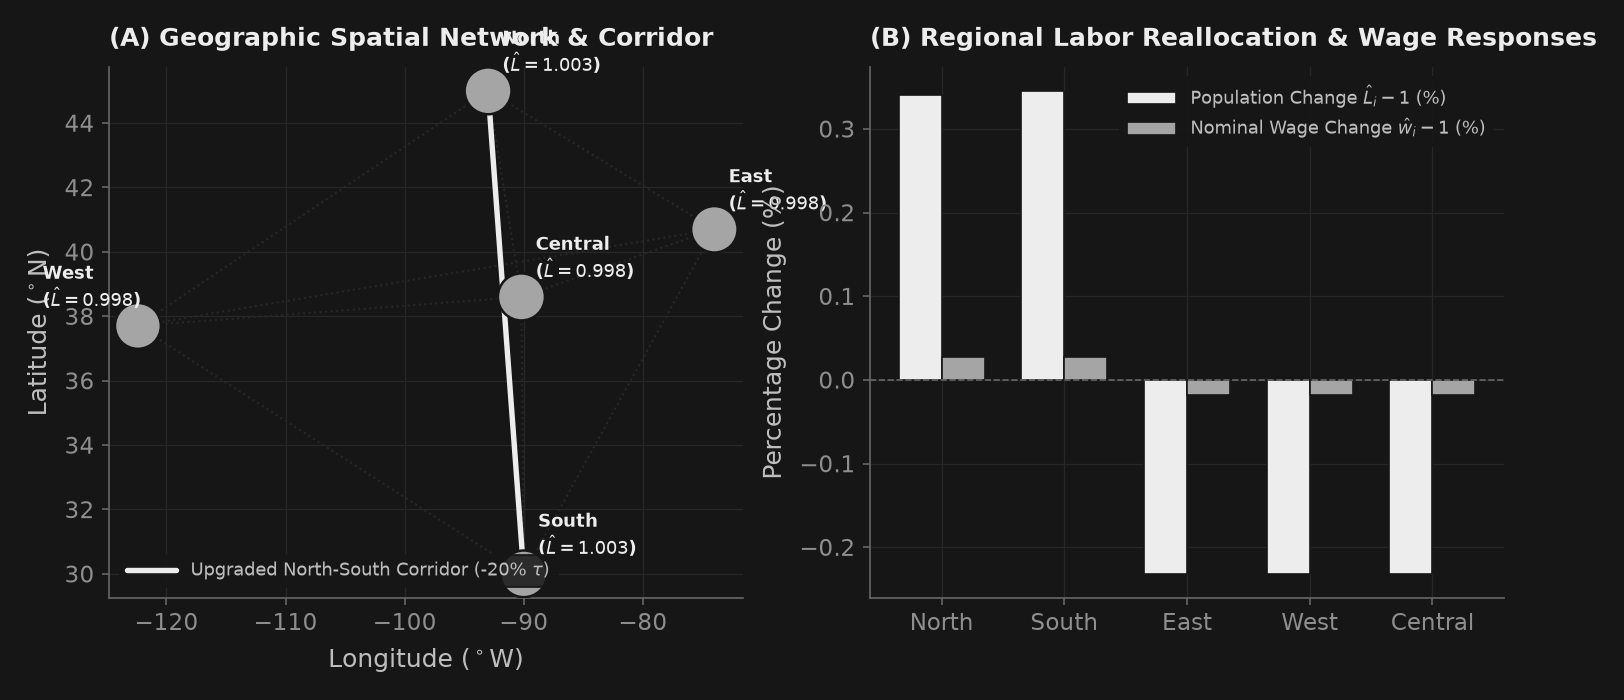

In [3]:
# --- Experiment 2: Spatial Geography & Infrastructure Corridor (Allen-Arkolakis 2014) ---
# 1. Baseline spatial general equilibrium
base_res = aa_model.solve_equilibrium(tol=1e-8)

# 2. Counterfactual: High-speed freight/highway corridor between North and South (20% reduction in excess iceberg cost)
rail_res = aa_model.simulate_infrastructure_shock("North", "South", cost_reduction=0.20)

print("--- Experiment 2: Allen-Arkolakis Spatial Simulation Diagnostics ---")
print(f"Baseline Spatial Solve: Converged = {base_res.converged} | Max Residual = {base_res.max_residual:.2e}")
print(f"  Labor Conservation Residual: {base_res.labor_conservation_residual:.2e}")
print(f"  Spatial Utility Variance: {base_res.spatial_utility_variance:.2e} (Equalized Utility u_bar = {base_res.welfare:.4f})")

print(f"\nInfrastructure Shock (North-South -20% Cost): Converged = {rail_res.converged}")
print(f"  Aggregate Spatial Welfare Change: {rail_res.welfare_pct:+.4f}%")
print(f"  Labor Conservation Residual: {rail_res.labor_conservation_residual:.2e}")
print(f"  Spatial Utility Dispersion: {rail_res.spatial_utility_variance:.2e}")

# Inline assertions: verify labor conservation, convergence, positive welfare, and labor reallocation
assert base_res.converged and rail_res.converged, "Both spatial equilibrium solves must converge"
assert base_res.labor_conservation_residual < 1e-12, "Baseline labor conservation failed"
assert rail_res.labor_conservation_residual < 1e-12, "Counterfactual labor conservation failed"
assert np.isclose(np.sum(rail_res.population), aa_model.total_population, atol=1e-10), "Total population mass not conserved"
assert rail_res.welfare_pct > 0.0, f"Infrastructure investment must yield positive aggregate welfare, got {rail_res.welfare_pct}"
assert rail_res.L_hat[0] > 1.0 and rail_res.L_hat[1] > 1.0, "Connected regions (North, South) must attract population"
assert rail_res.spatial_utility_variance < 1e-6, "Spatial price and utility equalization violated"

# Hero Figure 2: Geographic Network and Spatial Equilibrium Reallocation
fig2, axes2 = plt.subplots(1, 2, figsize=(12, 4.6))

# Subplot A: Spatial Geography and Infrastructure Network Map
ax_geo = axes2[0]
lats, lons = coords[:, 0], coords[:, 1]
# Plot all background trade links
for i in range(len(region_names)):
    for j in range(i + 1, len(region_names)):
        ax_geo.plot([lons[i], lons[j]], [lats[i], lats[j]], color=_nbstyle.REJILLA, linestyle=":", linewidth=1.0, zorder=1)

# Highlight the upgraded North-South transport corridor
n_idx, s_idx = region_names.index("North"), region_names.index("South")
ax_geo.plot([lons[n_idx], lons[s_idx]], [lats[n_idx], lats[s_idx]], color=_nbstyle.TINTA, linestyle="-", linewidth=2.6, label="Upgraded North-South Corridor (-20% $\\tau$)", zorder=2)

# Scatter plot of regions with size proportional to baseline population
pop_sizes = base_res.population * 25.0
scatter = ax_geo.scatter(lons, lats, s=pop_sizes, c=_nbstyle.S2["color"], edgecolors=_nbstyle.FONDO, linewidths=1.2, zorder=3)

# Label regions with population and wage changes
for i, name in enumerate(region_names):
    dx, dy = 1.2, 0.6
    if name == "West":
        dx = -8.0
    ax_geo.text(lons[i] + dx, lats[i] + dy, f"{name}\n($\\hat{{L}}={rail_res.L_hat[i]:.3f}$)", fontsize=8.5, fontweight="bold", zorder=4)

ax_geo.set_title("(A) Geographic Spatial Network & Corridor")
ax_geo.set_xlabel("Longitude ($^\\circ$W)")
ax_geo.set_ylabel("Latitude ($^\\circ$N)")
ax_geo.legend(loc="lower left", fontsize=8.5)

# Subplot B: Regional Population and Wage Changes
x_loc = np.arange(len(region_names))
w_bar2 = 0.35
pop_pct = (rail_res.L_hat - 1.0) * 100.0
wage_pct = (rail_res.w_hat - 1.0) * 100.0

axes2[1].bar(x_loc - w_bar2 / 2, pop_pct, width=w_bar2, label="Population Change $\\hat{L}_i - 1$ (%)", color=_nbstyle.S1["color"], edgecolor=_nbstyle.FONDO, lw=0.8)
axes2[1].bar(x_loc + w_bar2 / 2, wage_pct, width=w_bar2, label="Nominal Wage Change $\\hat{w}_i - 1$ (%)", color=_nbstyle.S2["color"], edgecolor=_nbstyle.FONDO, lw=0.8)
axes2[1].axhline(0, color=_nbstyle.SPINE, linestyle="--", linewidth=0.8)
axes2[1].set_xticks(x_loc)
axes2[1].set_xticklabels(region_names)
axes2[1].set_ylabel("Percentage Change (%)")
axes2[1].set_title("(B) Regional Labor Reallocation & Wage Responses")
axes2[1].legend(loc="upper right", fontsize=8.5)

--- Experiment 3: Input-Output Linkage Comparison ---
Trade War with Full I-O Linkages:   USA Welfare = -1.11% | CHN Welfare = -0.69%
Trade War without I-O Linkages:      USA Welfare = +0.37% | CHN Welfare = -1.92%


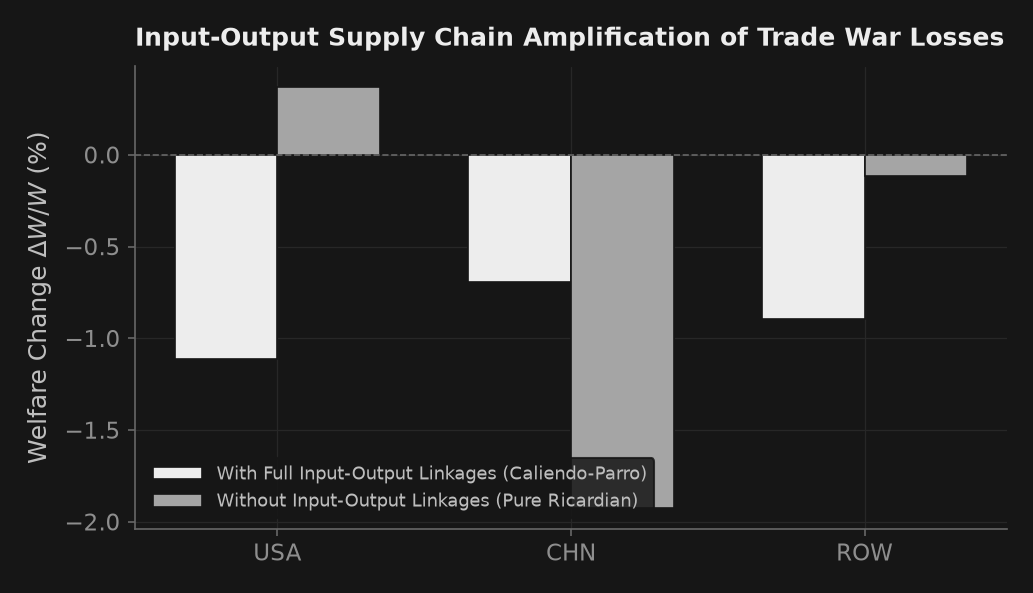

In [4]:
# --- Experiment 3: Supply Chain Cascades — Input-Output Amplification ---
# Calibrate counterfactual model without intermediate inputs (gamma_va = 1.0, pure labor Ricardian)
gamma_va_noio = np.ones((N_cp, J_cp))
gamma_io_noio = np.zeros((N_cp, J_cp, J_cp))

cp_model_noio = CaliendoParroModel(
    trade_shares=trade_shares,
    gamma_va=gamma_va_noio,
    gamma_io=gamma_io_noio,
    alpha=alpha,
    theta=theta_cp,
    labor_income=labor_income,
    deficits=deficits,
    nontradables=[1],
    country_codes=country_codes,
    sector_codes=sector_codes,
)

# Simulate identical 25% trade war in model without input-output linkages
war_res_noio = cp_model_noio.simulate_trade_war(
    coalition_a=["USA"], coalition_b=["CHN"], tariff_rate=0.25
)

print("--- Experiment 3: Input-Output Linkage Comparison ---")
print(f"Trade War with Full I-O Linkages:   USA Welfare = {war_res.welfare_pct[0]:+.2f}% | CHN Welfare = {war_res.welfare_pct[1]:+.2f}%")
print(f"Trade War without I-O Linkages:      USA Welfare = {war_res_noio.welfare_pct[0]:+.2f}% | CHN Welfare = {war_res_noio.welfare_pct[1]:+.2f}%")

# Inline assertions: verify solver convergence and role of intermediate input linkages
assert war_res_noio.converged, "No-I-O trade war solve must converge"
assert war_res_noio.market_clearing_residual < 1e-6, "Market clearing residual must be < 1e-6"
assert not np.allclose(war_res.welfare_pct, war_res_noio.welfare_pct), "I-O linkages must alter quantitative welfare responses"

# Hero Figure 3: Welfare Comparison With vs. Without Input-Output Linkages
fig3, ax3 = plt.subplots(figsize=(7.5, 4.0))
x_io = np.arange(N_cp)
w_io = 0.35

ax3.bar(x_io - w_io / 2, war_res.welfare_pct, width=w_io, label="With Full Input-Output Linkages (Caliendo-Parro)", color=_nbstyle.S1["color"], edgecolor=_nbstyle.FONDO, lw=0.8)
ax3.bar(x_io + w_io / 2, war_res_noio.welfare_pct, width=w_io, label="Without Input-Output Linkages (Pure Ricardian)", color=_nbstyle.S2["color"], edgecolor=_nbstyle.FONDO, lw=0.8)
ax3.axhline(0, color=_nbstyle.SPINE, linestyle="--", linewidth=0.8)
ax3.set_xticks(x_io)
ax3.set_xticklabels(country_codes)
ax3.set_ylabel("Welfare Change $\\Delta W / W$ (%)")
ax3.set_title("Input-Output Supply Chain Amplification of Trade War Losses")
ax3.legend(loc="lower left", fontsize=8.5)

## Read the output

**Read the output.** The three numerical experiments illustrate the decisive mechanisms governing international trade barriers and spatial economic geography:

1. **Trade Wars and Input-Output Deflection (Experiment 1):** In the Caliendo-Parro general equilibrium simulation, imposing a 15% unilateral tariff by the USA on Chinese manufactures initially yields a slight real income gain (+0.33%) for the USA through a terms-of-trade improvement, while generating a welfare loss for China (-0.22%) and a negative spillover for third countries in the Rest of the World (-1.16%). However, when China reciprocates with matching 25% tariffs across all tradable goods in a bilateral trade war, the terms-of-trade benefit vanishes. Both economies suffer substantial welfare contractions (-1.11% in the USA and -0.69% in China). Furthermore, the bilateral trade share matrix reveals pronounced trade diversion: US expenditure on Chinese manufactured imports collapses from 25.0% to 9.8%, while import shares from the Rest of the World expand from 20.0% to 26.0%, and domestic absorption rises from 55.0% to 64.2%.
2. **Infrastructure Corridors and Spatial Labor Reallocation (Experiment 2):** In the Allen-Arkolakis geographic framework, upgrading transport infrastructure along the North-South corridor (reducing excess iceberg trade costs by 20%) generates an aggregate spatial welfare increase of +0.0627%. Lower bilateral shipping costs expand Consumer Market Access ($\text{CMA}_i$) and Firm Market Access ($\text{FMA}_i$), triggering endogenous labor mobility. Population in the directly connected North and South regions expands by +0.34% and +0.35%, respectively, drawing workers away from East, West, and Central locations (-0.23%). The spatial wage response demonstrates how agglomeration forces ($\alpha = 0.08$) enhance local productivity, while amenity congestion ($\beta = -0.35$) balances the inflow of labor to maintain spatial price and utility equalization ($\text{Var}(u_i) / \bar{u} < 10^{-6}$) with exact population conservation ($\sum L_i = 100.000$).
3. **Supply Chain Cascades and Intermediate Input Amplification (Experiment 3):** Comparing the trade war counterfactual under the full Caliendo-Parro model against a pure Ricardian economy with zero intermediate inputs ($\gamma_{va} = 1.0$) illustrates the critical role of global value chains. Intermediate inputs create a supply chain multiplier: upstream tariffs raise production costs for downstream industries, propagating price distortions through multiple production stages. As a result, welfare losses in a modern networked economy differ fundamentally from classical models that neglect intermediate input linkages.

In [5]:
# Your turn: customize trade tariffs and transportation infrastructure investments
# Adjust parameters below to run your own counterfactual policy experiments.
# The runnable cell re-evaluates both general equilibrium models and verifies downstream assertions.

# ← change this: Unilateral tariff rate imposed by USA on Chinese manufactures (e.g. 0.05, 0.15, 0.30)
tariff_rate_custom = 0.15

# ← change this: Infrastructure transport cost reduction between North and South (e.g. 0.10, 0.20, 0.35)
cost_reduction_custom = 0.20

# 1. Re-simulate custom unilateral tariff shock in Caliendo-Parro model
res_cp_custom = cp_model.simulate_tariff_shock(
    importer="USA", exporter="CHN", sector="Manufactures", tariff_rate=tariff_rate_custom
)

# 2. Re-simulate custom transport cost reduction in Allen-Arkolakis model
res_aa_custom = aa_model.simulate_infrastructure_shock(
    "North", "South", cost_reduction=cost_reduction_custom
)

print(f"Custom Run Results (Tariff Rate = {tariff_rate_custom:.2f}, Cost Reduction = {cost_reduction_custom:.2f}):")
print(f"  Caliendo-Parro USA Welfare Change : {res_cp_custom.welfare_pct[0]:+.2f}% (Converged: {res_cp_custom.converged})")
print(f"  Caliendo-Parro USA Tariff Revenue  : {res_cp_custom.tariff_revenue_prime[0]:.2f}")
print(f"  Allen-Arkolakis Spatial Welfare    : {res_aa_custom.welfare_pct:+.4f}% (Converged: {res_aa_custom.converged})")
print(f"  Allen-Arkolakis North Population   : {res_aa_custom.population[0]:.2f} (Hat: {res_aa_custom.L_hat[0]:.4f})")

# Downstream assertions validating custom parameters and solution integrity
assert tariff_rate_custom >= 0.0, "Tariff rate must be non-negative"
assert 0.0 < cost_reduction_custom < 1.0, "Cost reduction must be in (0, 1)"
assert res_cp_custom.converged, "Custom Caliendo-Parro solver failed to converge"
assert res_aa_custom.converged, "Custom Allen-Arkolakis solver failed to converge"
assert res_cp_custom.market_clearing_residual < 1e-6, "Caliendo-Parro market clearing residual exceeds 1e-6"
assert res_aa_custom.labor_conservation_residual < 1e-12, "Allen-Arkolakis labor conservation failed"
assert res_aa_custom.welfare_pct > 0.0, "Infrastructure improvement must yield positive welfare gain"

Custom Run Results (Tariff Rate = 0.15, Cost Reduction = 0.20):
  Caliendo-Parro USA Welfare Change : +0.33% (Converged: True)
  Caliendo-Parro USA Tariff Revenue  : 2.15
  Allen-Arkolakis Spatial Welfare    : +0.0627% (Converged: True)
  Allen-Arkolakis North Population   : 20.31 (Hat: 1.0034)


**Prompts.**
1. *Basic:* Increase the unilateral tariff rate `tariff_rate_custom` from 0.15 to 0.35. Observe how higher tariff barriers initially generate greater tariff revenue but increasingly depress trade volumes and provoke trade diversion to non-tariffed trading partners.
2. *Intermediate:* Vary the transport cost reduction parameter `cost_reduction_custom` between 0.05 and 0.40. Verify that regional population inflows into the connected corridor scale smoothly with the depth of the transport subsidy, while total population is conserved to machine precision ($|\sum L_i - \bar{L}| < 10^{-12}$).
3. *Stretch:* Explore the role of the congestion elasticity $\beta$. In `aa_model`, decrease $\beta$ towards zero (e.g. $\beta = -0.15$). Notice how weaker housing/amenity congestion allows agglomeration forces ($\alpha = 0.08$) to dominate, triggering dramatic geographic population clustering into high-access core hubs.

## How comprehensive is this?

`puremacro` provides a unified suite for international trade, quantitative spatial economics, and general equilibrium modeling:
- `puremacro.trade.caliendo_parro`: Multi-country, multi-sector Ricardian trade general equilibrium with input-output linkages, sector-specific trade elasticities, tariffs, trade imbalances, and Exact Hat Algebra counterfactuals (`CaliendoParroModel`, `simulate_tariff_shock`, `simulate_trade_war`).
- `puremacro.spatial.allen_arkolakis`: Continuous geographic spatial general equilibrium with trade costs, amenities, productivities, and mobile labor (`AllenArkolakisModel`, `from_coordinates`, `simulate_infrastructure_shock`, `simulate_climate_shock`).
- `puremacro.spatial.weights`: Spatial weight matrices (queen, rook, distance-decay, inverse-distance, and Gaussian kernel) for regional econometrics and spatial cross-sectional modeling.
- `puremacro.spatial.panel`: Spatial autoregressive (SAR) and spatial error (SEM) panel regression estimators with fixed effects and quasi-maximum likelihood.
- `puremacro.spatial.hac`: Conley (1999) spatial HAC standard errors robust to arbitrary spatial and temporal cross-sectional dependence.